GAN Lab — From Random Digits to Requested Digits
Name: Anant Arya
Roll number: A24ARIU0014

A shortened, beginner-friendly version of the lab: train an unconditional GAN, change only the discriminator learning rate, then train a conditional GAN that receives digit labels. The default is a quick run for checking the code. Increase EPOCHS and TRAIN_LIMIT for meaningful sample quality.

In [6]:
import random
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LATENT_DIM = 100
BATCH_SIZE = 128
EPOCHS = 1          # Fast check; use 10 or more for a longer experiment.
TRAIN_LIMIT = 2048  # Use None for all training images.
LR = 2e-4


def seed_all(seed=SEED):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all()
print("Device:", DEVICE, "| epochs:", EPOCHS, "| training limit:", TRAIN_LIMIT)

Device: cpu | epochs: 1 | training limit: 2048


In [7]:
# Pixels are scaled to [-1, 1] to match the generators' Tanh output.
transform28 = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])
train28 = datasets.MNIST("./data", train=True, download=True, transform=transform28)
if TRAIN_LIMIT is not None:
    train28 = Subset(train28, range(min(TRAIN_LIMIT, len(train28))))
print("Training images:", len(train28))
criterion = nn.BCEWithLogitsLoss()  # Discriminators output logits (no sigmoid).

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.99MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 159kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.50MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.60MB/s]

Training images: 2048


3. Simple GAN and alternating updates
During the discriminator step, fake images are detached so gradients update only D. During the generator step, D is frozen but gradients still flow through D to G.

In [8]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(LATENT_DIM, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 784), nn.Tanh(),
        )
    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
        )
    def forward(self, image):
        return self.net(image.flatten(start_dim=1))


def discriminator_step(G, D, opt_g, opt_d, real):
    batch_size = real.size(0)
    opt_d.zero_grad(set_to_none=True)
    z = torch.randn(batch_size, LATENT_DIM, device=DEVICE)
    fake = G(z).detach()  # Detach: update D only in this step.
    real_loss = criterion(D(real), torch.ones(batch_size, 1, device=DEVICE))
    fake_loss = criterion(D(fake), torch.zeros(batch_size, 1, device=DEVICE))
    loss = real_loss + fake_loss
    loss.backward()
    opt_d.step()
    return loss.item()


def generator_step(G, D, opt_g, batch_size):
    opt_g.zero_grad(set_to_none=True)
    for p in D.parameters():
        p.requires_grad_(False)
    z = torch.randn(batch_size, LATENT_DIM, device=DEVICE)
    fake = G(z)  # Do not detach: G needs the gradient through D.
    loss = criterion(D(fake), torch.ones(batch_size, 1, device=DEVICE))
    loss.backward()
    opt_g.step()
    for p in D.parameters():
        p.requires_grad_(True)
    return loss.item()


# Basic forward-shape check before training.
G, D = Generator().to(DEVICE), Discriminator().to(DEVICE)
assert G(torch.randn(4, LATENT_DIM, device=DEVICE)).shape == (4, 784)
assert D(torch.randn(4, 784, device=DEVICE)).shape == (4, 1)
print("GAN shape checks passed")

GAN shape checks passed


Train baseline and faster-discriminator comparison

Baseline epoch 1/1: D=0.944, G=0.627
Faster D epoch 1/1: D=0.761, G=0.820


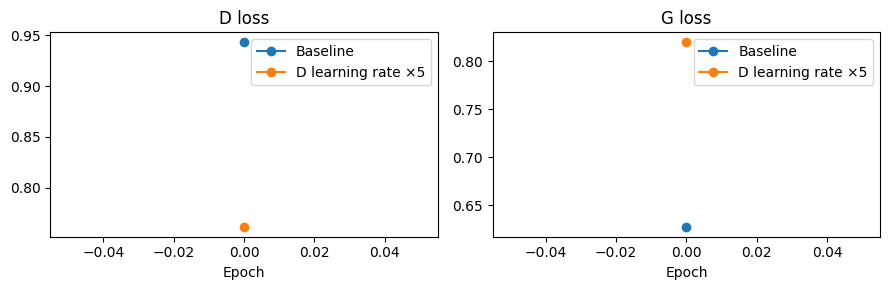

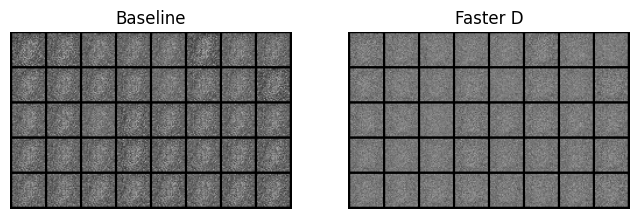

In [9]:
def train_gan(name, d_lr_scale=1.0, conditional=False, epochs=EPOCHS):
    # Reset seed and shuffle order so baseline/intervention start comparably.
    seed_all(SEED)
    G = (ConditionalGenerator() if conditional else Generator()).to(DEVICE)
    D = (ConditionalDiscriminator() if conditional else Discriminator()).to(DEVICE)
    opt_g = torch.optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(D.parameters(), lr=LR * d_lr_scale, betas=(0.5, 0.999))
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(train32 if conditional else train28, batch_size=BATCH_SIZE,
                        shuffle=True, drop_last=True, generator=generator)
    history = {"D": [], "G": []}
    for epoch in range(epochs):
        d_total = g_total = 0.0
        for batch, labels in loader:
            batch = batch.to(DEVICE)
            if conditional:
                labels = labels.to(DEVICE)
                d_loss = discriminator_step_cond(G, D, opt_g, opt_d, batch, labels)
                g_loss = generator_step_cond(G, D, opt_g, batch.size(0), labels)
            else:
                d_loss = discriminator_step(G, D, opt_g, opt_d, batch)
                g_loss = generator_step(G, D, opt_g, batch.size(0))
            d_total += d_loss; g_total += g_loss
        history["D"].append(d_total / len(loader)); history["G"].append(g_total / len(loader))
        print(f"{name} epoch {epoch+1}/{epochs}: D={history['D'][-1]:.3f}, G={history['G'][-1]:.3f}")
    return {"G": G, "D": D, "history": history}

baseline = train_gan("Baseline")
faster_d = train_gan("Faster D", d_lr_scale=5.0)

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for axis, key in zip(ax, ["D", "G"]):
    axis.plot(baseline["history"][key], marker="o", label="Baseline")
    axis.plot(faster_d["history"][key], marker="o", label="D learning rate ×5")
    axis.set_title(key + " loss"); axis.set_xlabel("Epoch"); axis.legend()
plt.tight_layout(); plt.show()

# Reuse the same noise to compare the generators fairly.
fixed_z = torch.randn(40, LATENT_DIM, device=DEVICE)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for axis, name, result in zip(ax, ["Baseline", "Faster D"], [baseline, faster_d]):
    with torch.no_grad():
        samples = (result["G"](fixed_z).reshape(-1, 1, 28, 28).cpu() + 1) / 2
    axis.imshow(make_grid(samples.clamp(0, 1), nrow=8).permute(1,2,0), cmap="gray")
    axis.set_title(name); axis.axis("off")
plt.show()

5. Conditional GAN: request a digit
The conditional model receives the same one-hot digit condition in both G and D. D still returns one real/fake score per image.

In [10]:
NUM_CLASSES = 10
IMG_SIZE = 32

# Conditioning helpers: append the one-hot digit vector to noise or image channels.
def condition_noise(noise, labels):
    one_hot = F.one_hot(labels, num_classes=NUM_CLASSES).to(dtype=noise.dtype)
    return torch.cat([noise, one_hot], dim=1).view(-1, LATENT_DIM + NUM_CLASSES, 1, 1)


def condition_images(images, labels):
    one_hot = F.one_hot(labels, num_classes=NUM_CLASSES).to(dtype=images.dtype)
    maps = one_hot[:, :, None, None].expand(-1, -1, images.size(2), images.size(3))
    return torch.cat([images, maps], dim=1)


class ConditionalGenerator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(110, 256, 4, 1, 0, bias=False), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1, bias=False), nn.Tanh(),
        )
    def forward(self, noise, labels):
        return self.net(condition_noise(noise, labels))


class ConditionalDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(11, 64, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, 2, 1, bias=False), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 1, 4, 1, 0, bias=False),
        )
    def forward(self, images, labels):
        return self.net(condition_images(images, labels)).flatten(1)


def discriminator_step_cond(G, D, opt_g, opt_d, real, labels):
    n = real.size(0); opt_d.zero_grad(set_to_none=True)
    z = torch.randn(n, LATENT_DIM, device=DEVICE)
    fake = G(z, labels).detach()
    loss = criterion(D(real, labels), torch.ones(n, 1, device=DEVICE)) + criterion(D(fake, labels), torch.zeros(n, 1, device=DEVICE))
    loss.backward(); opt_d.step(); return loss.item()


def generator_step_cond(G, D, opt_g, batch_size, labels):
    opt_g.zero_grad(set_to_none=True)
    was_training = D.training
    for p in D.parameters(): p.requires_grad_(False)
    D.eval()  # Freeze BatchNorm statistics, but keep gradients through D to G.
    z = torch.randn(batch_size, LATENT_DIM, device=DEVICE)
    loss = criterion(D(G(z, labels), labels), torch.ones(batch_size, 1, device=DEVICE))
    loss.backward(); opt_g.step()
    for p in D.parameters(): p.requires_grad_(True)
    D.train(was_training)
    return loss.item()

# Resize MNIST to 32x32 for the convolutional conditional GAN.
transform32 = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))
])
train32 = datasets.MNIST("./data", train=True, download=True, transform=transform32)
if TRAIN_LIMIT is not None:
    train32 = Subset(train32, range(min(TRAIN_LIMIT, len(train32))))
labels_test = torch.tensor([0, 3, 7, 9], device=DEVICE)
noise_test = torch.randn(4, LATENT_DIM, device=DEVICE)
assert condition_noise(noise_test, labels_test).shape == (4, 110, 1, 1)
assert condition_images(torch.zeros(4,1,32,32,device=DEVICE), labels_test).shape == (4,11,32,32)
print("Conditioning shape checks passed")

Conditioning shape checks passed


6. Train and inspect conditional generation

Conditional GAN epoch 1/1: D=0.403, G=0.942


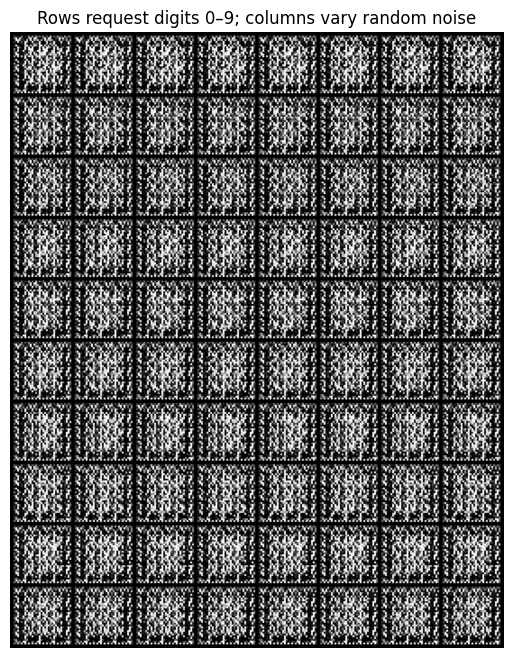

In [11]:
conditional = train_gan("Conditional GAN", conditional=True)

# Fix noise and request each digit from 0 to 9.
labels = torch.arange(NUM_CLASSES, device=DEVICE).repeat_interleave(8)
noise = torch.randn(NUM_CLASSES, LATENT_DIM, device=DEVICE).repeat_interleave(8, dim=0)
with torch.no_grad():
    samples = (conditional["G"](noise, labels).cpu() + 1) / 2
plt.figure(figsize=(8, 8))
plt.imshow(make_grid(samples.clamp(0, 1), nrow=8).permute(1,2,0), cmap="gray")
plt.title("Rows request digits 0–9; columns vary random noise")
plt.axis("off"); plt.show()

7. Short lab answers
- Why detach fake images for D? So the discriminator update cannot send gradients into the generator.
- Why not detach fake images for G? The generator needs gradients through D's score to update its own weights. D's weights are frozen during this step.
- What does a 5× discriminator learning rate change? It makes D update more aggressively. Compare the plotted losses and identical-noise samples; with a quick run, do not treat sample quality as conclusive.
- How to tell whether labels or noise are ignored? If labels are ignored, changing requested class barely changes the digit. If noise is ignored, samples requested for the same class look nearly identical.
- Why does conditional D output one score instead of ten? Its task is real-versus-fake for each image-condition pair. The class is provided as input, not predicted as the target.
Run note: EPOCHS = 1 is only a fast execution check. It does not establish image quality. For the lab comparison, increase EPOCHS (e.g. 10) and preferably set TRAIN_LIMIT = None, then record observations from your actual plots.